# code_001 · Decision trees: rules, complexity and controlled experiments

**Book home:** Chapter 18, subtopic 18.1 — Decision trees and recursive partitioning.  
**Permanent ID:** `code_001` · **File:** `001_Chapter_18_01_Decision_Tree.ipynb`.

A tree learns a sequence of threshold questions. This notebook makes those questions visible, then changes each constructor control in isolation before studying an interaction. Its synthetic examples are teaching devices, not measured evidence about buildings or structural safety. The main two-feature task has abstract coordinates; a separate ordered-feature example uses invented load/resistance values only to demonstrate monotonic constraints.

By the end you should be able to trace a prediction to a leaf, explain the difference between a label and a probability, diagnose underfitting/overfitting, compare all 13 exposed constructor parameters, and select a configuration without tuning on the final test set. Prerequisites are Python functions, arrays, basic classification metrics, and the training/validation/test distinction. Chapters 4, 5, 7, 14, 36 and 37 supply the supporting concepts.

**How to run:** use the repository [quickstart](../README.md) and pinned [requirements](../requirements.txt), select that Python environment in your notebook editor, restart the kernel, and run all cells in order. The reference run uses CPython 3.14.3, scikit-learn 1.9.0 and CPU only; actual versions, timing and hardware are printed below and at the end. No downloads, private data, API keys, GPU or imports from this repository are required during an ordinary run. Allow roughly 1–2 minutes for execution and 60–90 minutes to work through the questions; the measured reference runtime is in [EXECUTION_REPORT.md](../EXECUTION_REPORT.md). Plot rendering and first-use font caching can change runtime.

**Reading route:** [mechanism](#mechanism) → [data and evaluation contract](#data-contract) → [model guide](#model-guide) → [parameter map](#parameter-map) → [experiments](#depth) → [interaction and choice](#interaction) → [final assessment](#final-test) → [exercises](#exercises).

Make a prediction before each experiment. The supplied outputs are observations from an executed run; they are not universal rules about which setting is best. Re-running exploratory comparisons on this fixed validation set does not make it fresh evidence. After extensive adaptation, use a new external assessment rather than reusing the final test set.


In [1]:
import sys, platform, time, inspect, math, hashlib
from datetime import datetime
from zoneinfo import ZoneInfo
import numpy as np
import scipy
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from IPython.display import display
import sklearn
from sklearn.datasets import make_moons, make_classification
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, log_loss,
                             brier_score_loss, precision_score, recall_score,
                             confusion_matrix, ConfusionMatrixDisplay)

START = time.perf_counter()
SEED = 418
# Deliberately fixed before viewing validation results. Only this grid selects the final model.
FINAL_DEPTHS = [2, 3, 4, 6, 10, None]
FINAL_LEAVES = [1, 5, 20, 50]
VERSIONS = {'python': platform.python_version(), 'numpy': np.__version__,
            'scipy': scipy.__version__, 'pandas': pd.__version__,
            'matplotlib': matplotlib.__version__, 'scikit-learn': sklearn.__version__}
print('Versions:', VERSIONS)
print('Hardware:', platform.system(), platform.machine(), '| CPU; no GPU used')
print('Run date:', datetime.now(ZoneInfo('Australia/Melbourne')).isoformat(timespec='seconds'))
assert sklearn.__version__ == '1.9.0', 'Use the pinned environment for the verified reference run.'
plt.rcParams.update({'figure.dpi': 100, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.constrained_layout.use': True,
                     'savefig.facecolor': 'white'})
covered = set()
def mark(*names):
    covered.update(names)


Versions: {'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
Hardware: Darwin arm64 | CPU; no GPU used
Run date: 2026-10-18T17:28:56+11:00


<a id="mechanism"></a>
## The mechanism: ask a question, follow a branch, summarize a leaf

Imagine dividing a feature plane with one horizontal or vertical cut. A tree repeats such cuts inside each remaining region. During `fit`, it searches candidate feature thresholds and prefers a split that improves a class-purity objective subject to its restrictions. It is a greedy sequence, not an exhaustive search for the globally best tree. A later split cannot revise the earlier question; small data changes can therefore produce different trees.

At prediction time, a record follows the learned questions to one terminal leaf. The class distribution in that training leaf supplies a probability estimate; choosing its most probable class gives a label. There is no gradient-descent parameter update in this estimator. Complexity controls and pruning decide how far the partition is allowed to grow.

**Figure 1 caption and textual alternative:** a training-only search creates threshold questions. A new record follows a fixed branch to a leaf. That leaf's training-label composition determines its class probabilities. Arrows mean computation, not causal relationships. The toy counts below illustrate a leaf; they are not the fitted model's results.


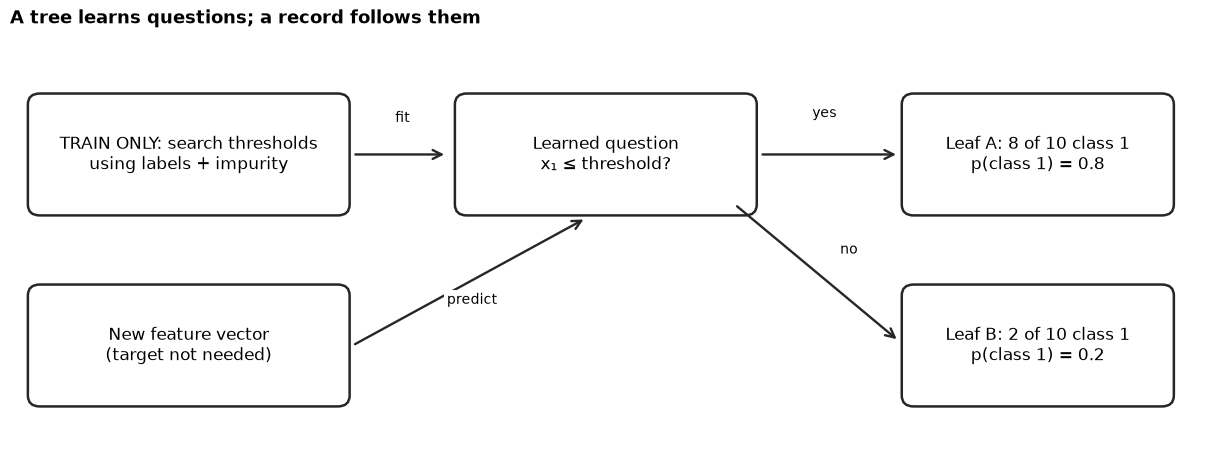

In [2]:
fig, ax = plt.subplots(figsize=(12, 4.4))
ax.set(xlim=(0, 12), ylim=(0, 4.5)); ax.axis('off')
def box(x, y, w, h, text):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.12',
                              fc='white', ec='0.15', lw=1.8))
    ax.text(x+w/2, y+h/2, text, ha='center', va='center', fontsize=12)
def arrow(a, b, label, label_xy):
    ax.add_patch(FancyArrowPatch(a, b, arrowstyle='->', mutation_scale=16, color='0.15', lw=1.7))
    ax.text(*label_xy, label, ha='center', va='center', fontsize=10,
            bbox={'facecolor':'white', 'edgecolor':'none', 'pad':2})
box(.3, 2.6, 3.0, 1.1, 'TRAIN ONLY: search thresholds\nusing labels + impurity')
box(4.6, 2.6, 2.8, 1.1, 'Learned question\nx₁ ≤ threshold?')
box(.3, .5, 3.0, 1.1, 'New feature vector\n(target not needed)')
box(9.1, 2.6, 2.5, 1.1, 'Leaf A: 8 of 10 class 1\np(class 1) = 0.8')
box(9.1, .5, 2.5, 1.1, 'Leaf B: 2 of 10 class 1\np(class 1) = 0.2')
arrow((3.45,3.15),(4.4,3.15),'fit',(3.95,3.55))
arrow((3.45,1.05),(5.8,2.45),'predict',(4.65,1.55))
arrow((7.55,3.15),(8.95,3.15),'yes',(8.2,3.6))
arrow((7.3,2.6),(8.95,1.1),'no',(8.45,2.1))
ax.set_title('A tree learns questions; a record follows them', loc='left', weight='bold')
plt.show()


<a id="data-contract"></a>
## Data and evaluation contract

The main task is binary classification on 1,800 locally generated noisy two-moon observations (`make_moons`, seed 418, coordinate noise 0.27). Curved class regions make axis-aligned partitions easy to inspect. Class 1 is simply the generator's second class; feature axes have no physical units or engineering interpretation. Rows are independent synthetic observations, so a stratified random split is a reasonable teaching design. Repeated buildings, sequences or sites would require grouped or temporal splitting instead.

We split row identifiers into 60% training, 20% validation and 20% final test, with disjointness assertions. All exploration, pruning paths and hyperparameter experiments use training/validation only. The final test features and labels are materialized only in the final-assessment cell, after the chosen configuration is fixed. Stratification uses class labels solely to allocate the splits; it does not fit a model or choose a setting.

The **selection metric is validation balanced accuracy** (mean recall across the two classes). We also report ordinary accuracy, probability log loss, tree depth and leaf count. A probability score matters because a hard leaf prediction can be confidently wrong. No probability calibration or deployment-quality claim follows from good classification accuracy alone. We compare with a training-prior dummy classifier. There is no scaling step: numeric threshold splits already compare ordered values within one feature; standardizing the two coordinates is unnecessary for this example.

Weighted, imbalanced, extra-noise-feature and monotonic examples later use explicitly named **auxiliary development data** to isolate a mechanism that the main task would not reveal well. Their validation scores are demonstrations, not final held-out performance claims; none changes the main task's final selection grid.


Rows: {'training': 1080, 'validation': 360, 'sealed final test': 360}
Split-ID SHA256: 96ab00b0fa2dde44d7b71f57df079bdef3cdad5cb31f0a67eb3682ea82ca205f
Training class counts: [540 540] | validation: [180 180]


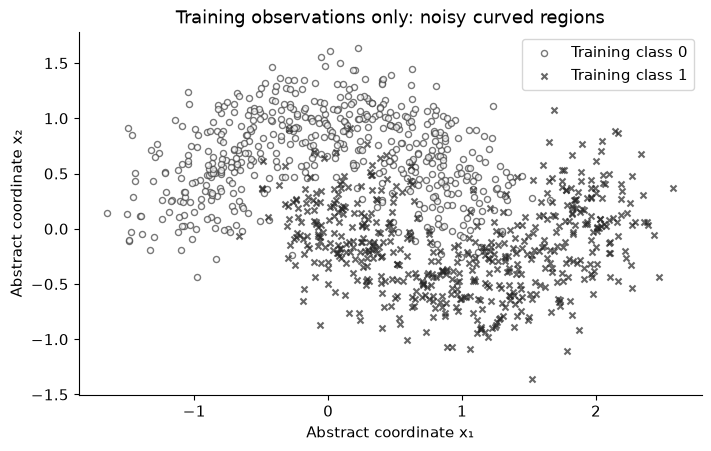

In [3]:
X_all, y_all = make_moons(n_samples=1800, noise=.27, random_state=SEED)
row_ids = np.arange(len(y_all))
dev_ids, test_ids = train_test_split(row_ids, test_size=.2, stratify=y_all, random_state=SEED)
train_ids, val_ids = train_test_split(dev_ids, test_size=.25, stratify=y_all[dev_ids], random_state=SEED+1)
assert not (set(train_ids) & set(val_ids) or set(train_ids) & set(test_ids) or set(val_ids) & set(test_ids))
assert len(set(train_ids) | set(val_ids) | set(test_ids)) == len(row_ids)
X_train, y_train = X_all[train_ids], y_all[train_ids]
X_val, y_val = X_all[val_ids], y_all[val_ids]
TEST_REVEALED = False
print('Rows:', {'training':len(train_ids), 'validation':len(val_ids), 'sealed final test':len(test_ids)})
print('Split-ID SHA256:', hashlib.sha256(np.concatenate([train_ids,val_ids,test_ids]).tobytes()).hexdigest())
print('Training class counts:', np.bincount(y_train), '| validation:', np.bincount(y_val))

fig, ax = plt.subplots(figsize=(7, 4.4))
for label, marker, face in [(0,'o','white'), (1,'x','0.15')]:
    mask=y_train==label
    ax.scatter(*X_train[mask].T, s=19, marker=marker, c=face,
               edgecolors='0.25' if label==0 else None, alpha=.7, label=f'Training class {label}')
ax.set(xlabel='Abstract coordinate x₁', ylabel='Abstract coordinate x₂', title='Training observations only: noisy curved regions')
ax.legend(); plt.show()


<a id="model-guide"></a>
## A first fitted model and the API you will use

`DecisionTreeClassifier(...)` creates an unfitted estimator. `fit(X_train, y_train)` learns its questions and leaf distributions and returns that same estimator. `predict(X)` returns one class label per row. `predict_proba(X)` returns one row of probabilities per example, with columns ordered by `classes_`. They are fitted leaf proportions (weighted proportions when weights are used), not a separate confidence guarantee. `apply(X)` reports the terminal leaf identifiers and `decision_path(X)` identifies the visited nodes. `get_depth()` and `get_n_leaves()` describe learned complexity.

Start with a depth-three tree for interpretation, not because three is universally optimal. The following helpers are defined here and use only the data passed to them. They will give every comparison the same metrics and axis definitions. In decision-boundary plots, pale versus dark background regions indicate predicted class, while circles versus crosses show observed labels; the distinction survives grayscale printing.


In [4]:
def scores(model, X, y):
    pred=model.predict(X)
    proba=model.predict_proba(X)
    return {'accuracy':accuracy_score(y,pred), 'balanced_accuracy':balanced_accuracy_score(y,pred),
            'log_loss':log_loss(y,proba,labels=[0,1])}

def comparison(model, Xtr=X_train, ytr=y_train, Xv=X_val, yv=y_val):
    tr=scores(model,Xtr,ytr); va=scores(model,Xv,yv)
    return {'train_bal_acc':tr['balanced_accuracy'], 'val_bal_acc':va['balanced_accuracy'],
            'val_accuracy':va['accuracy'], 'val_log_loss':va['log_loss'],
            'depth':model.get_depth(), 'leaves':model.get_n_leaves()}

def boundary(ax, model, X, y, title):
    lo=X.min(axis=0)-.35; hi=X.max(axis=0)+.35
    gx,gy=np.meshgrid(np.linspace(lo[0],hi[0],180),np.linspace(lo[1],hi[1],180))
    zz=model.predict(np.c_[gx.ravel(),gy.ravel()]).reshape(gx.shape)
    ax.contourf(gx,gy,zz,levels=[-.5,.5,1.5],cmap=ListedColormap(['.92','.65']),alpha=.9)
    for label,marker in [(0,'o'),(1,'x')]:
        mask=y==label
        ax.scatter(*X[mask].T,s=14,marker=marker,c='white' if label==0 else '.1',
                   edgecolors='.15' if label==0 else None, linewidths=.7,label=f'Observed {label}')
    ax.set(title=title,xlabel='Abstract x₁',ylabel='Abstract x₂')

def sweep(parameter, values, *, Xtr=X_train, ytr=y_train, Xv=X_val, yv=y_val,
          base=None, weights=None, title=None):
    rows=[]; models=[]
    for value in values:
        params={'random_state':SEED}
        params.update(base or {}); params[parameter]=value
        model=DecisionTreeClassifier(**params).fit(Xtr,ytr,sample_weight=weights)
        rows.append({'setting':str(value), **comparison(model,Xtr,ytr,Xv,yv)})
        models.append(model)
    table=pd.DataFrame(rows)
    pos=np.arange(len(values))
    fig,axes=plt.subplots(1,2,figsize=(11,3.7))
    axes[0].plot(pos,table.train_bal_acc,'o--',color='.45',label='Training')
    axes[0].plot(pos,table.val_bal_acc,'s-',color='black',label='Validation')
    axes[0].set(ylabel='Balanced accuracy',ylim=(.4,1.02)); axes[0].legend()
    axes[1].plot(pos,table.leaves,'d-',color='.2'); axes[1].set(ylabel='Learned leaves')
    for ax in axes:
        ax.set_xticks(pos,[f'{v:.3g}' if isinstance(v,(float,np.floating)) else str(v) for v in values],rotation=25,ha='right')
        ax.set_xlabel(parameter + ' (categorical settings)')
    fig.suptitle(title or f'Change only {parameter}; all other settings fixed')
    plt.show(); display(table.round(4))
    mark(parameter)
    return table,models

intro=DecisionTreeClassifier(max_depth=3,random_state=SEED)
assert intro.fit(X_train,y_train) is intro
baseline=DummyClassifier(strategy='prior').fit(X_train,y_train)
print('Validation baseline:',scores(baseline,X_val,y_val))
print('Validation depth-three tree:',scores(intro,X_val,y_val))
print('classes_:',intro.classes_,'| predict shape:',intro.predict(X_val[:3]).shape,
      '| predict_proba shape:',intro.predict_proba(X_val[:3]).shape)
assert np.allclose(intro.predict_proba(X_val[:3]).sum(axis=1),1)
print(export_text(intro,feature_names=['abstract_x1','abstract_x2']))


Validation baseline: {'accuracy': 0.5, 'balanced_accuracy': 0.5, 'log_loss': 0.6931471805599453}
Validation depth-three tree: {'accuracy': 0.9055555555555556, 'balanced_accuracy': 0.9055555555555556, 'log_loss': 0.24879178127062546}
classes_: [0 1] | predict shape: (3,) | predict_proba shape: (3, 2)
|--- abstract_x2 <= 0.41
|   |--- abstract_x1 <= -0.50
|   |   |--- abstract_x1 <= -0.67
|   |   |   |--- class: 0
|   |   |--- abstract_x1 >  -0.67
|   |   |   |--- class: 0
|   |--- abstract_x1 >  -0.50
|   |   |--- abstract_x2 <= -0.06
|   |   |   |--- class: 1
|   |   |--- abstract_x2 >  -0.06
|   |   |   |--- class: 1
|--- abstract_x2 >  0.41
|   |--- abstract_x1 <= 1.49
|   |   |--- abstract_x2 <= 0.70
|   |   |   |--- class: 0
|   |   |--- abstract_x2 >  0.70
|   |   |   |--- class: 0
|   |--- abstract_x1 >  1.49
|   |   |--- class: 1



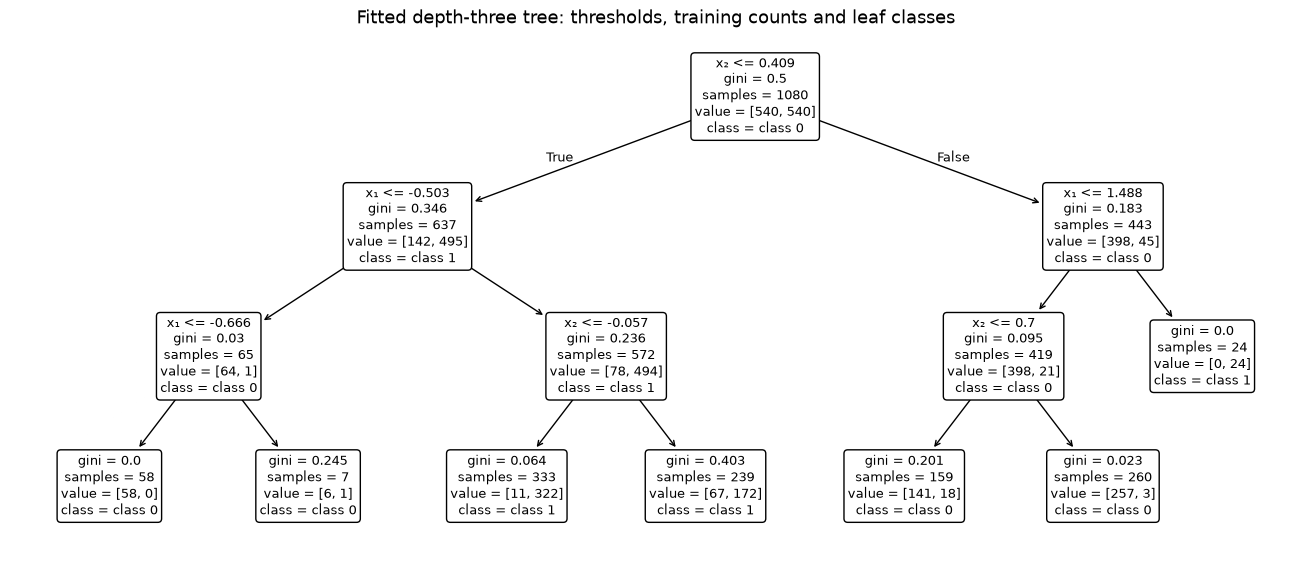

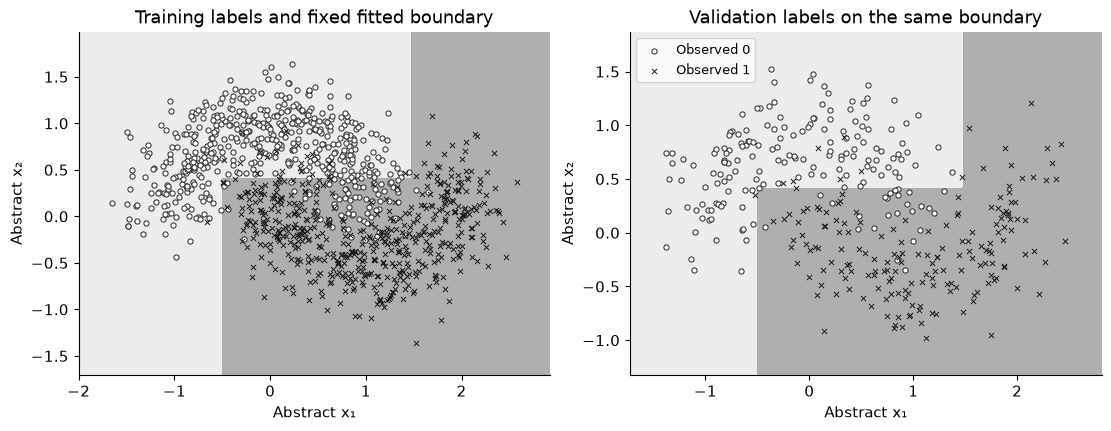

First validation record: [1.93930679 0.62709564] | terminal leaf: 12
Training-label counts in that leaf: [ 0 24]
Leaf fractions: [0. 1.] | API: [0. 1.]


In [5]:
fig,ax=plt.subplots(figsize=(13,5.5))
plot_tree(intro,ax=ax,feature_names=['x₁','x₂'],class_names=['class 0','class 1'],
          rounded=True,filled=False,impurity=True,proportion=False,fontsize=9)
ax.set_title('Fitted depth-three tree: thresholds, training counts and leaf classes')
plt.show()
fig,axes=plt.subplots(1,2,figsize=(11,4.2))
boundary(axes[0],intro,X_train,y_train,'Training labels and fixed fitted boundary')
boundary(axes[1],intro,X_val,y_val,'Validation labels on the same boundary')
axes[1].legend(loc='upper left',fontsize=9); plt.show()
# Verify the probability meaning for one actual validation record.
leaf=intro.apply(X_val[:1])[0]
in_leaf=intro.apply(X_train)==leaf
leaf_counts=np.bincount(y_train[in_leaf],minlength=2)
print('First validation record:',X_val[0], '| terminal leaf:',leaf)
print('Training-label counts in that leaf:',leaf_counts)
print('Leaf fractions:',leaf_counts/leaf_counts.sum(), '| API:',intro.predict_proba(X_val[:1])[0])
assert np.allclose(leaf_counts/leaf_counts.sum(),intro.predict_proba(X_val[:1])[0])


**Read the figures:** every internal node asks one threshold question. The two children inherit different subsets of training records; a terminal leaf stores the class mix. Trace the first validation record manually and check the leaf printed above. The plotted `value` entries are class counts for this unweighted fit. Rectangular prediction regions follow from axis-aligned cuts, even though the underlying moon shapes are curved. The validation panel reuses the already fitted tree and does not update it.

**Pause:** can a perfectly pure training leaf still give a wrong validation prediction? What happens to log loss if it assigns probability zero to the observed class? When would you prefer a shallower rule that is slightly less accurate but cheaper to inspect? The tables report both label and probability quality to keep these questions visible.


<a id="parameter-map"></a>
## Parameter coverage map

This table covers the complete constructor returned by the **installed scikit-learn 1.9.0**. Defaults below are checked against the live object. The [official 1.9 API reference](https://scikit-learn.org/1.9/modules/generated/sklearn.tree.DecisionTreeClassifier.html) currently renders the 1.9 maintenance documentation; the notebook itself is pinned to 1.9.0. The [tree guide](https://scikit-learn.org/1.9/modules/tree.html) and [pruning example](https://scikit-learn.org/1.9/auto_examples/tree/plot_cost_complexity_pruning.html) provide primary technical background. Explanations, data and experiment designs here are original; no benchmark superiority is claimed.

| Parameter | Default | Role and experiment |
| --- | --- | --- |
| `criterion` | `'gini'` | Split-quality objective; [Gini versus entropy, including the log-loss alias](#criterion). |
| `splitter` | `'best'` | Candidate-threshold search; [best versus randomized search over fixed seeds](#splitter). |
| `max_depth` | `None` | Limits levels of questions; [complexity curves and boundaries](#depth). |
| `min_samples_split` | `2` | Minimum parent count before another split; [count/fraction sweep](#min-split). |
| `min_samples_leaf` | `1` | Minimum support in each child; [count/fraction sweep and equivalence](#min-leaf). |
| `min_weight_fraction_leaf` | `0.0` | Minimum fraction of total training weight per leaf; [non-uniform-weight demonstration](#min-weight). |
| `max_features` | `None` | Restricts feature candidates; [signal plus noise-feature experiment](#max-features). |
| `random_state` | `None` | Reproducibility and stochastic variation; [repeatability and multi-seed diagnostic](#random-state). |
| `max_leaf_nodes` | `None` | Caps terminal regions; [leaf-budget sweep](#max-leaves). |
| `min_impurity_decrease` | `0.0` | Requires a minimum weighted improvement; [split-acceptance sweep](#impurity). |
| `class_weight` | `None` | Changes class contributions during fitting; [imbalanced development task](#class-weight). |
| `ccp_alpha` | `0.0` | Penalizes complexity after growth; [training-only pruning path](#pruning). |
| `monotonic_cst` | `None` | Enforces specified ordered effects on positive-class probability; [valid ordered-feature task](#monotonic). |

Most experiments hold the dataset, row split and tree seed fixed and change one setting; other constructor defaults stay unchanged unless the cell explicitly states otherwise. Integer and fractional controls are demonstrated separately. Repeated seeds are deliberate only for the stochastic comparisons. Accuracy need not improve monotonically as any control increases; more complexity and better evidence are different things.


In [6]:
expected_defaults={'criterion':'gini','splitter':'best','max_depth':None,'min_samples_split':2,
 'min_samples_leaf':1,'min_weight_fraction_leaf':0.,'max_features':None,'random_state':None,
 'max_leaf_nodes':None,'min_impurity_decrease':0.,'class_weight':None,'ccp_alpha':0.,'monotonic_cst':None}
actual_params=DecisionTreeClassifier().get_params(deep=False)
assert actual_params == expected_defaults, 'API/defaults changed: update the coverage map before teaching this version.'
print(inspect.signature(DecisionTreeClassifier))
print('Constructor parameters:',len(actual_params))


(*, criterion='gini', splitter='best', max_depth=None, min_samples_split=2, min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features=None, random_state=None, max_leaf_nodes=None, min_impurity_decrease=0.0, class_weight=None, ccp_alpha=0.0, monotonic_cst=None)
Constructor parameters: 13


<a id="depth"></a>
## Experiment: `max_depth` — how many questions may a path ask?

**Predict first:** will unlimited depth improve training performance, validation performance, both, or neither? A depth cap limits the longest root-to-leaf path, not the total number of leaves. With few levels the tree may miss curved regions. With many levels it can isolate noisy observations and produce fragile, highly confident leaves. `None` removes this particular cap; other restrictions still apply.

We change only depth below, then inspect depth 1, 3 and unrestricted boundaries on validation records. Read the gap between training and validation alongside the number of learned leaves; the most detailed picture need not be the best-supported one. All results are conditional on this one fixed development split.


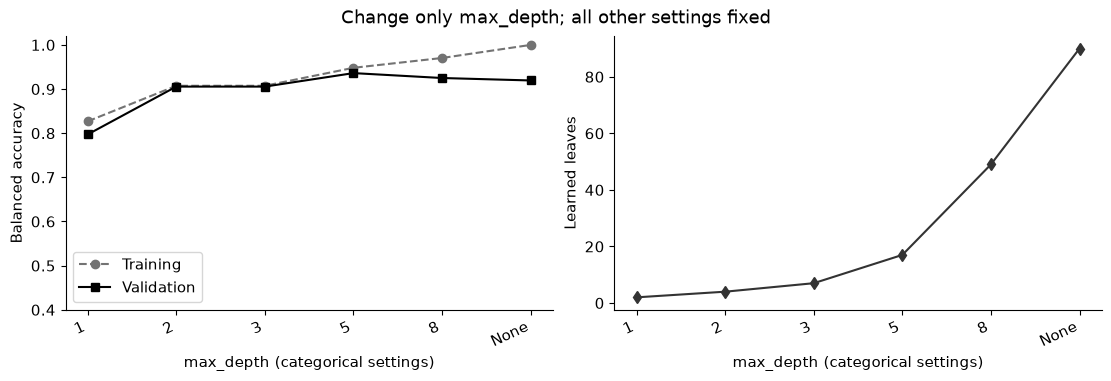

,setting,train_bal_acc,val_bal_acc,val_accuracy,val_log_loss,depth,leaves
0,1,0.8269,0.7972,0.7972,0.4997,1,2
1,2,0.9074,0.9056,0.9056,0.3003,2,4
2,3,0.9074,0.9056,0.9056,0.2488,3,7
3,5,0.9481,0.9361,0.9361,0.3706,5,17
4,8,0.9704,0.9250,0.9250,1.5715,8,49
5,None,1.0000,0.9194,0.9194,2.9035,15,90


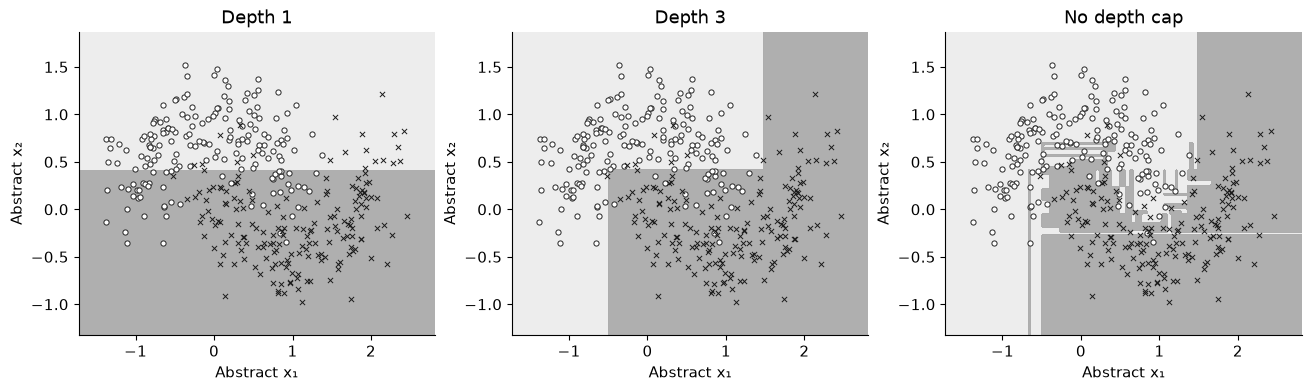

In [7]:
depth_table,depth_models=sweep('max_depth',[1,2,3,5,8,None])
fig,axes=plt.subplots(1,3,figsize=(13,3.8))
for ax,index,label in zip(axes,[0,2,5],['Depth 1','Depth 3','No depth cap']):
    boundary(ax,depth_models[index],X_val,y_val,label)
plt.show()


**Interpretation prompt:** identify a region where the unrestricted tree follows isolated observations. Compare its validation log loss with its label accuracy. A declining validation score while training score grows suggests overfitting on this experiment; a flat validation curve can also reflect finite-sample uncertainty, so do not generalize the exact best depth to another dataset.

<a id="min-split"></a>
## Experiment: `min_samples_split` — require evidence in the parent

A node must contain enough training rows before the estimator considers dividing it. An integer is a count; a float is a fraction of the complete fitting sample count, rounded upward. Requiring 50 rows in the parent does not require 25 rows in each child: a very uneven split can still pass this control. `min_samples_leaf` addresses the child support directly.

**Predict first:** for 1,080 training rows, what count does 0.05 require? Will this guarantee that every leaf contains that many rows? Inspect minimum leaf size as well as the score curve to answer rather than relying on the parameter's name.


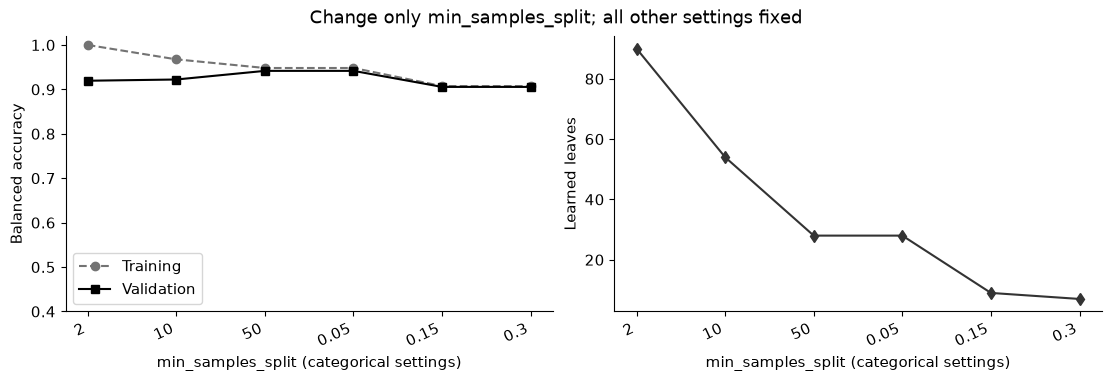

,setting,train_bal_acc,val_bal_acc,val_accuracy,val_log_loss,depth,leaves
0,2,1.0000,0.9194,0.9194,2.9035,15,90
1,10,0.9676,0.9222,0.9222,1.9554,12,54
2,50,0.9481,0.9417,0.9417,0.6080,8,28
3,0.05,0.9481,0.9417,0.9417,0.6080,8,28
4,0.15,0.9074,0.9056,0.9056,0.3046,4,9
5,0.3,0.9074,0.9056,0.9056,0.3364,4,7


,setting,required_parent_rows,smallest_leaf_rows
0,2,2,1
1,10,10,1
2,50,50,1
3,0.05,54,1
4,0.15,162,24
5,0.3,324,24


In [8]:
split_values=[2,10,50,.05,.15,.30]
split_table,split_models=sweep('min_samples_split',split_values)
display(pd.DataFrame({'setting':list(map(str,split_values)),
 'required_parent_rows':[v if isinstance(v,int) else math.ceil(v*len(y_train)) for v in split_values],
 'smallest_leaf_rows':[int(m.tree_.n_node_samples[m.tree_.children_left==-1].min()) for m in split_models]}))


<a id="min-leaf"></a>
## Experiment: `min_samples_leaf` — require support in both children

A proposed split must leave enough rows in both children. This usually removes small islands and smooths estimated probabilities, but it can also erase a real rare subgroup. Counts and fractions have different behaviour when the training set grows: a fixed fraction demands more observations, while a fixed count stays fixed. Fractions use the fitting set's total row count, rounded upward, not the current parent's count.

**Predict first:** which constraint is stricter, 20 rows per child or 0.02 of 1,080 rows? The explicit equivalence check below compares 0.02 with its computed count, holding every other setting fixed. The table verifies the minimum support of actual leaves. Compare probability log loss as well as balanced accuracy; larger leaves can moderate extreme probabilities without guaranteeing calibration.


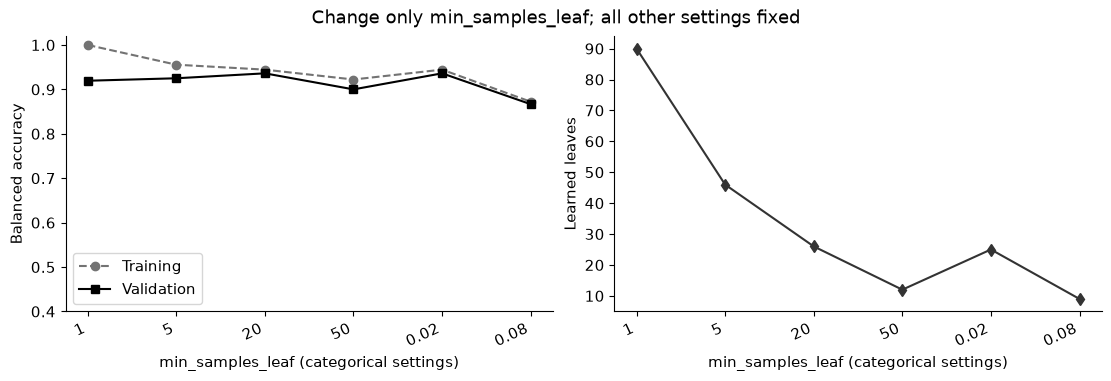

,setting,train_bal_acc,val_bal_acc,val_accuracy,val_log_loss,depth,leaves
0,1,1.0000,0.9194,0.9194,2.9035,15,90
1,5,0.9556,0.9250,0.9250,1.0025,10,46
2,20,0.9444,0.9361,0.9361,0.5371,8,26
3,50,0.9222,0.9000,0.9000,0.3077,5,12
4,0.02,0.9444,0.9361,0.9361,0.5374,8,25
5,0.08,0.8722,0.8667,0.8667,0.4013,5,9


,setting,required_min_rows,observed_min_rows
0,1,1,1
1,5,5,5
2,20,20,20
3,50,50,50
4,0.02,22,22
5,0.08,87,87


0.02 equals a minimum of 22 rows for this fit.


In [9]:
leaf_values=[1,5,20,50,.02,.08]
leaf_table,leaf_models=sweep('min_samples_leaf',leaf_values)
required=[v if isinstance(v,int) else math.ceil(v*len(y_train)) for v in leaf_values]
observed=[int(m.tree_.n_node_samples[m.tree_.children_left==-1].min()) for m in leaf_models]
assert all(a>=b for a,b in zip(observed,required))
display(pd.DataFrame({'setting':list(map(str,leaf_values)),'required_min_rows':required,'observed_min_rows':observed}))
equivalent=DecisionTreeClassifier(random_state=SEED,min_samples_leaf=math.ceil(.02*len(y_train))).fit(X_train,y_train)
assert np.array_equal(equivalent.tree_.feature,leaf_models[4].tree_.feature)
assert np.allclose(equivalent.predict_proba(X_val),leaf_models[4].predict_proba(X_val))
print('0.02 equals a minimum of',math.ceil(.02*len(y_train)),'rows for this fit.')


<a id="max-leaves"></a>
## Experiment: `max_leaf_nodes` — budget the number of terminal regions

This control caps the number of leaves and grows an allowed tree by choosing beneficial splits under that budget. It constrains total regions rather than the length of every path. A tree with six leaves may have an uneven shape and need not resemble a depth-three tree. `None` removes the leaf budget.

**Predict first:** could a tree with only six leaves have depth greater than three? Inspect both learned depth and leaves. Compare the fixed-budget tree with the earlier depth-limited example: they express different resource and interpretability choices, even when their scores are similar. The assertion checks only the promised leaf budget, not a universal accuracy trend.


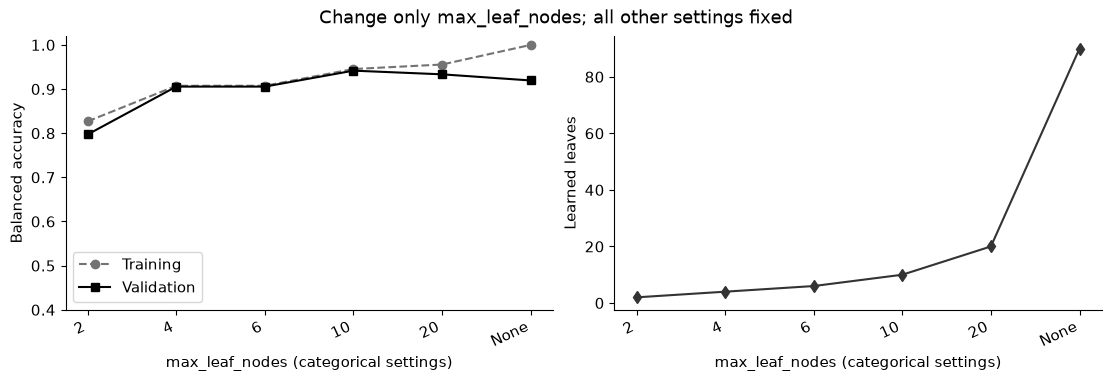

,setting,train_bal_acc,val_bal_acc,val_accuracy,val_log_loss,depth,leaves
0,2,0.8269,0.7972,0.7972,0.4997,1,2
1,4,0.9074,0.9056,0.9056,0.3003,2,4
2,6,0.9074,0.9056,0.9056,0.2306,4,6
3,10,0.9454,0.9417,0.9417,0.2037,7,10
4,20,0.9556,0.9333,0.9333,0.7680,9,20
5,None,1.0000,0.9194,0.9194,2.9035,15,90


In [10]:
leaf_budgets=[2,4,6,10,20,None]
budget_table,budget_models=sweep('max_leaf_nodes',leaf_budgets)
for cap,model in zip(leaf_budgets,budget_models):
    assert cap is None or model.get_n_leaves()<=cap


<a id="impurity"></a>
## Experiment: `min_impurity_decrease` — reject small improvements

A split must improve the weighted impurity objective by at least this threshold. The improvement accounts for the node's share of total fitting weight, so a local purity gain in a tiny node contributes less globally than the same gain in a large node. This is a growth restriction; it is different from pruning an already grown tree with `ccp_alpha`.

**Predict first:** will increasing the threshold mostly prevent early large splits or small refinements? Large values can produce a stump. Compare the learned leaves, training score and validation score; the setting with least complexity can still underfit. The threshold is tied to the objective and weights, so transferring the exact number to a different loss or sampling scheme requires care.


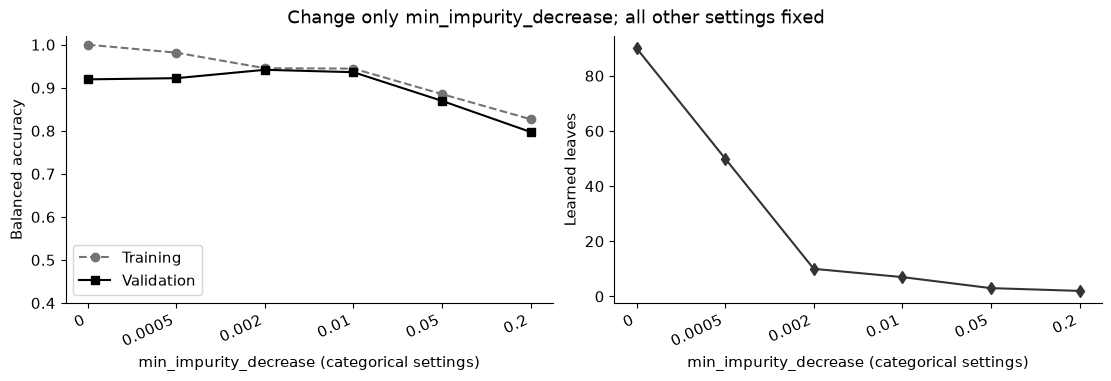

,setting,train_bal_acc,val_bal_acc,val_accuracy,val_log_loss,depth,leaves
0,0.0,1.0000,0.9194,0.9194,2.9035,15,90
1,0.0005,0.9815,0.9222,0.9222,1.9989,11,50
2,0.002,0.9454,0.9417,0.9417,0.2037,7,10
3,0.01,0.9444,0.9361,0.9361,0.2120,5,7
4,0.05,0.8852,0.8694,0.8694,0.3870,2,3
5,0.2,0.8269,0.7972,0.7972,0.4997,1,2


In [11]:
impurity_table,impurity_models=sweep('min_impurity_decrease',[0.,.0005,.002,.01,.05,.20])


<a id="criterion"></a>
## Experiment: `criterion` — what makes a child distribution useful?

Gini impurity and Shannon entropy reward purer class groups using different functions of class proportions. Different objectives can prefer different thresholds, although they often agree on easy splits. In this implementation `entropy` and `log_loss` are names for the same Shannon-information split criterion, not two independent algorithms. This constructor setting describes split selection; it does not mean a tree is trained by gradient descent on the validation log loss.

**Predict first:** should the two equivalent names produce identical predictions under fixed data and seed? We compare objectives with a fixed depth of four to inspect meaningful structure rather than allowing every criterion to isolate all rows. Check the alias equality and compare Gini's score and leaf count without assuming one objective wins generally.


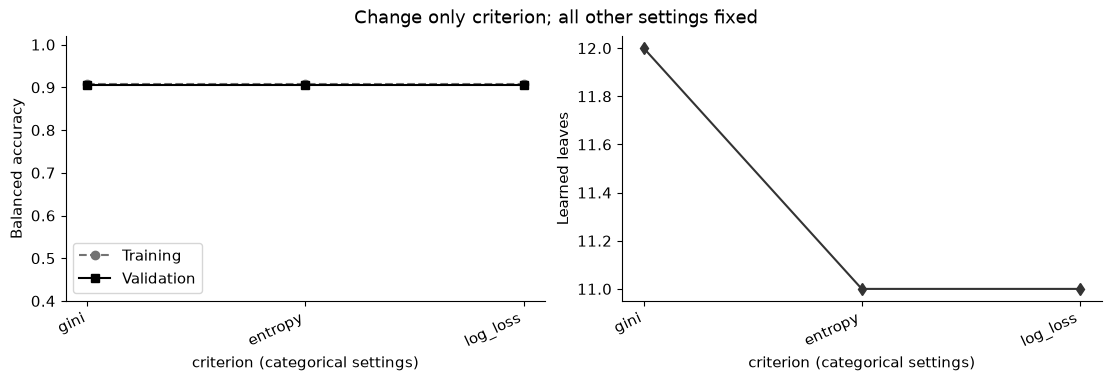

,setting,train_bal_acc,val_bal_acc,val_accuracy,val_log_loss,depth,leaves
0,gini,0.9083,0.9056,0.9056,0.3847,4,12
1,entropy,0.9083,0.9056,0.9056,0.3988,4,11
2,log_loss,0.9083,0.9056,0.9056,0.3988,4,11


Verified entropy/log_loss alias equality on this controlled fit.


In [12]:
criterion_table,criterion_models=sweep('criterion',['gini','entropy','log_loss'],base={'max_depth':4})
assert np.array_equal(criterion_models[1].tree_.feature,criterion_models[2].tree_.feature)
assert np.allclose(criterion_models[1].tree_.threshold,criterion_models[2].tree_.threshold)
assert np.allclose(criterion_models[1].predict_proba(X_val),criterion_models[2].predict_proba(X_val))
print('Verified entropy/log_loss alias equality on this controlled fit.')


<a id="splitter"></a>
## Experiment: `splitter` — best search versus randomized candidates

The best splitter searches for favourable thresholds; the random splitter randomizes candidate thresholds before selecting among available choices. Randomization changes how a tree is learned, not just how output rows are ordered. Its effects interact with depth, available features and the sampled data. One lucky seed is not enough evidence for choosing a stochastic strategy.

Both variants below use the same depth cap of five and the same eight seeds on the same row split. The plot shows individual validation scores plus mean and sample spread. The spread describes seed variation for this fixed dataset, not uncertainty across new populations or independent train/test splits. The default best strategy can also vary when candidate features are permuted or equally good alternatives occur.

**Predict first:** which strategy will have more variation? Could a random splitter occasionally outperform the best splitter on validation data even with a worse training objective?


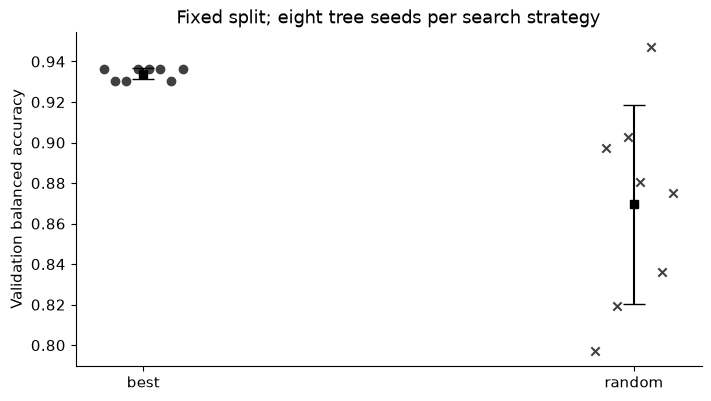

train_bal_acc         val_bal_acc         leaves        
                  mean     std        mean     std   mean     std
splitter                                                         
best            0.9481  0.0000      0.9340  0.0029  17.00  0.0000
random          0.8603  0.0536      0.8694  0.0492  16.75  3.6936

In [13]:
seed_rows=[]
for splitter in ['best','random']:
    for seed in range(8):
        model=DecisionTreeClassifier(splitter=splitter,max_depth=5,random_state=seed).fit(X_train,y_train)
        seed_rows.append({'splitter':splitter,'seed':seed,**comparison(model)})
seed_results=pd.DataFrame(seed_rows)
fig,ax=plt.subplots(figsize=(7,3.9))
for i,name in enumerate(['best','random']):
    values=seed_results.loc[seed_results.splitter==name,'val_bal_acc'].to_numpy()
    ax.scatter(i+np.linspace(-.08,.08,len(values)),values,marker='o' if i==0 else 'x',color='.25')
    ax.errorbar(i,values.mean(),yerr=values.std(ddof=1),fmt='s',color='black',capsize=8)
ax.set_xticks([0,1],['best','random']); ax.set(ylabel='Validation balanced accuracy',title='Fixed split; eight tree seeds per search strategy')
plt.show(); display(seed_results.groupby('splitter')[['train_bal_acc','val_bal_acc','leaves']].agg(['mean','std']).round(4))
mark('splitter')


<a id="random-state"></a>
## Experiment: `random_state` — reproducibility is an operational control

An integer seed lets you repeat stochastic choices within the pinned implementation. It does not improve the learning objective and should not become a hidden hyperparameter search for the best validation result. `None` delegates to an unfixed random source; passing a mutable random generator can advance its state across fits. Cross-version, hardware or numerical changes can still affect reproducibility, so record versions and the data split too.

The demonstration refits the same randomized tree twice with seed seven, then compares eight predeclared seeds. Exact equality is expected for the repeated fit in this environment. Different seeds may change the learned boundary or labels even when aggregate scores remain close.

**Reader question:** why is reporting the mean over all predeclared seeds more credible than publishing only the largest score? Use the disagreement with seed zero as an additional diagnostic rather than interpreting tiny score differences as proof of superiority.


In [14]:
a=DecisionTreeClassifier(splitter='random',max_depth=5,random_state=7).fit(X_train,y_train)
b=DecisionTreeClassifier(splitter='random',max_depth=5,random_state=7).fit(X_train,y_train)
assert np.array_equal(a.tree_.threshold,b.tree_.threshold)
assert np.array_equal(a.predict(X_val),b.predict(X_val))
reference=DecisionTreeClassifier(splitter='random',max_depth=5,random_state=0).fit(X_train,y_train)
random_rows=[]
for seed in range(8):
    model=DecisionTreeClassifier(splitter='random',max_depth=5,random_state=seed).fit(X_train,y_train)
    random_rows.append({'seed':seed,'disagreement_vs_seed_0':np.mean(model.predict(X_val)!=reference.predict(X_val)),
                        'val_bal_acc':balanced_accuracy_score(y_val,model.predict(X_val))})
random_table=pd.DataFrame(random_rows)
print('Same seed repeated: exact structure and label agreement verified.')
display(random_table.round(4)); mark('random_state')


Same seed repeated: exact structure and label agreement verified.


,seed,disagreement_vs_seed_0,val_bal_acc
0,0,0.0000,0.7972
1,1,0.2444,0.8972
2,2,0.1778,0.8194
3,3,0.1889,0.9028
4,4,0.2500,0.8806
5,5,0.1833,0.9472
6,6,0.0889,0.8361
7,7,0.1611,0.8750


<a id="max-features"></a>
## Experiment: `max_features` — which inputs may compete at a split?

With only two informative coordinates, feature subsampling can look like an arbitrary handicap. We therefore append four independently generated noise columns to training and validation **after** the main row split. The problem still has the same labels. This auxiliary view demonstrates how a restricted candidate set can omit a useful variable or introduce variability. It does not justify adding noise features to a real model.

We fix depth five and minimum leaf size five. `None` considers all six columns; counts, fractions, `sqrt` and `log2` specify candidate budgets. The fitted `max_features_` diagnostic shows the resolved count, which can coincide for different spellings. The search may inspect additional features when needed to find a valid partition, so this is not a guaranteed wall-clock cost cap.

**Predict first:** what integer budget do `sqrt` and `log2` give for six inputs? Does ignoring most columns reliably help this single tree? Compare training and validation changes rather than importing random-forest intuitions uncritically.


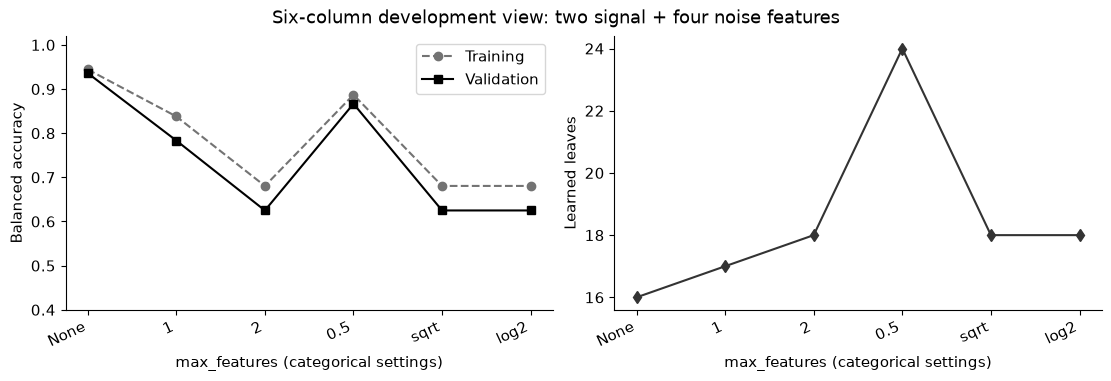

,setting,train_bal_acc,val_bal_acc,val_accuracy,val_log_loss,depth,leaves
0,None,0.9444,0.9361,0.9361,0.4710,5,16
1,1,0.8380,0.7833,0.7833,0.4711,5,17
2,2,0.6806,0.6250,0.6250,0.8112,5,18
3,0.5,0.8870,0.8667,0.8667,0.7751,5,24
4,sqrt,0.6806,0.6250,0.6250,0.8112,5,18
5,log2,0.6806,0.6250,0.6250,0.8112,5,18


,setting,resolved_candidate_budget
0,None,6
1,1,1
2,2,2
3,0.5,3
4,sqrt,2
5,log2,2


In [15]:
noise_rng=np.random.default_rng(SEED+20)
X_noise_train=np.column_stack([X_train,noise_rng.normal(size=(len(X_train),4))])
X_noise_val=np.column_stack([X_val,noise_rng.normal(size=(len(X_val),4))])
feature_values=[None,1,2,.5,'sqrt','log2']
feature_table,feature_models=sweep('max_features',feature_values,Xtr=X_noise_train,Xv=X_noise_val,
                                  base={'max_depth':5,'min_samples_leaf':5},
                                  title='Six-column development view: two signal + four noise features')
display(pd.DataFrame({'setting':list(map(str,feature_values)),
                      'resolved_candidate_budget':[m.max_features_ for m in feature_models]}))


<a id="min-weight"></a>
## Experiment: `min_weight_fraction_leaf` — counts are not fitting mass

Weights change how strongly rows contribute during fitting. Here we deliberately give training rows with x₁ > 1 a weight of nine and other rows a weight of one. These invented weights create an unequal-mass example; they are not inferred reliability estimates or a recommended policy for the moon task. Validation remains unweighted so that we can see the consequence for the original distribution.

`min_weight_fraction_leaf` requires every leaf to hold a minimum fraction of the **total training weight**. This differs from requiring a count of rows. The diagnostic checks weighted mass directly, and reports minimum row count alongside it. No class weights are applied in this experiment.

**Predict first:** can two leaves with equal row counts have different weight fractions? At fraction 0.08, could a child containing only a handful of high-weight rows satisfy the same mass constraint as many low-weight rows? Explain why the row minimum and weighted minimum need not track each other.


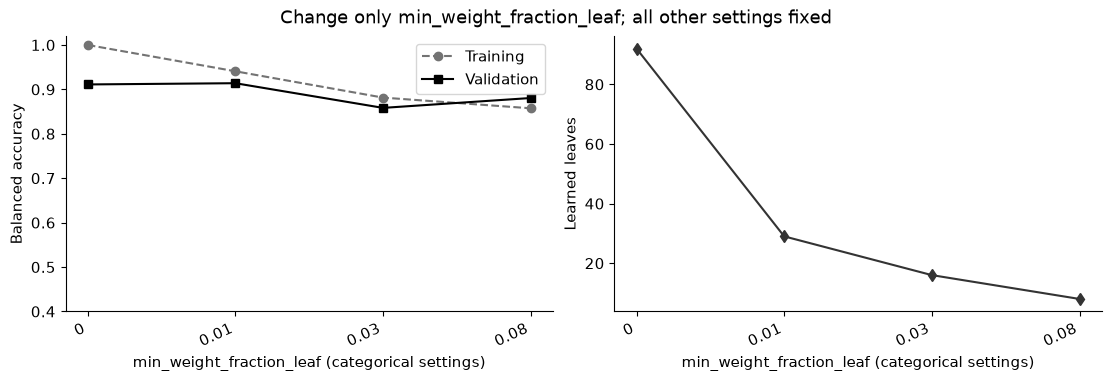

,setting,train_bal_acc,val_bal_acc,val_accuracy,val_log_loss,depth,leaves
0,0.0,1.0000,0.9111,0.9111,3.2039,14,92
1,0.01,0.9407,0.9139,0.9139,0.4966,8,29
2,0.03,0.8815,0.8583,0.8583,0.2595,5,16
3,0.08,0.8574,0.8806,0.8806,0.3157,4,8


,required_fraction,observed_min_weight_fraction,smallest_leaf_rows
0,0.00,0.0003,1
1,0.01,0.0102,5
2,0.03,0.0302,13
3,0.08,0.0816,33


In [16]:
training_weights=np.where(X_train[:,0]>1.,9.,1.)
weight_values=[0.,.01,.03,.08]
weight_table,weight_models=sweep('min_weight_fraction_leaf',weight_values,weights=training_weights)
weight_rows=[]
for value,model in zip(weight_values,weight_models):
    leaves=model.tree_.children_left==-1
    fractions=model.tree_.weighted_n_node_samples[leaves]/training_weights.sum()
    assert fractions.min()>=value-1e-12
    weight_rows.append({'required_fraction':value,'observed_min_weight_fraction':fractions.min(),
                        'smallest_leaf_rows':model.tree_.n_node_samples[leaves].min()})
display(pd.DataFrame(weight_rows).round(4))


<a id="class-weight"></a>
## Experiment: `class_weight` — change the fitting objective for rare outcomes

The main moons are approximately balanced. To make weighting visible, we generate a separate imbalanced binary dataset with a nominal 90/10 mixture, two informative numeric features, one cluster per class and 4% label-flip noise. We allocate 75% to auxiliary training and 25% to auxiliary validation. There is no auxiliary final test claim. This example has no physical meaning.

The default treats each class according to its observed frequency. `'balanced'` assigns training-derived inverse-frequency class weights; an explicit dictionary defines a different tradeoff. We keep depth three and leaf size twenty fixed, and compare minority recall, precision, balanced accuracy, predicted-positive counts and confusion matrices on the same unweighted validation data. Weights are not probabilities or guaranteed real-world error costs. If `sample_weight` is also supplied, class and row weights combine multiplicatively.

**Predict first:** can minority recall rise while precision or ordinary accuracy falls? Read the false positives and false negatives separately before choosing a weighting policy. Returned weighted leaf probabilities may need separate calibration for the deployment population; do not interpret weighting as a universal correction to probability quality.


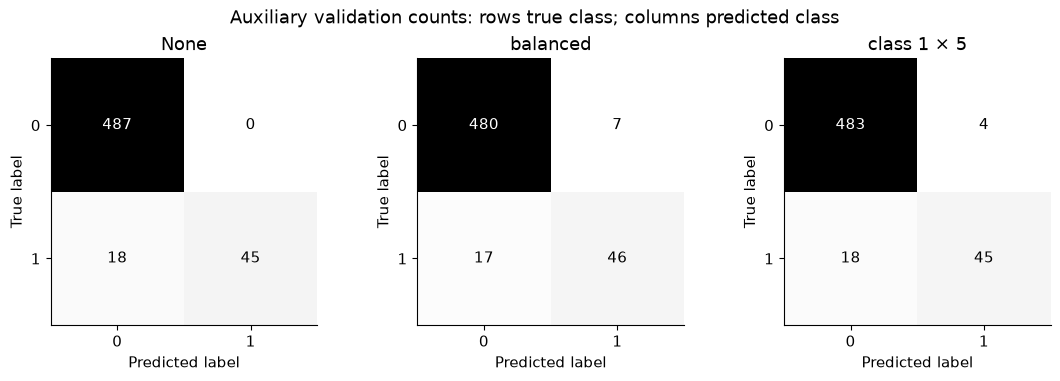

,class_weight,precision_1,recall_1,balanced_accuracy,accuracy,predicted_positive
0,None,1.0000,0.7143,0.8571,0.9673,45
1,balanced,0.8679,0.7302,0.8579,0.9564,53
2,class 1 × 5,0.9184,0.7143,0.8530,0.9600,49


Auxiliary training classes: [1463  187] | validation: [487  63]


In [17]:
Xi,yi=make_classification(n_samples=2200,n_features=2,n_informative=2,n_redundant=0,
                         n_clusters_per_class=1,weights=[.9,.1],flip_y=.04,class_sep=.8,random_state=SEED+30)
Xi_tr,Xi_va,yi_tr,yi_va=train_test_split(Xi,yi,test_size=.25,stratify=yi,random_state=SEED)
weight_options=[('None',None),('balanced','balanced'),('class 1 × 5',{0:1,1:5})]
class_rows=[]; class_models=[]
fig,axes=plt.subplots(1,3,figsize=(11,3.7))
for ax,(label,value) in zip(axes,weight_options):
    model=DecisionTreeClassifier(max_depth=3,min_samples_leaf=20,class_weight=value,random_state=SEED).fit(Xi_tr,yi_tr)
    pred=model.predict(Xi_va); class_models.append(model)
    class_rows.append({'class_weight':label,'precision_1':precision_score(yi_va,pred,zero_division=0),
       'recall_1':recall_score(yi_va,pred),'balanced_accuracy':balanced_accuracy_score(yi_va,pred),
       'accuracy':accuracy_score(yi_va,pred),'predicted_positive':int(pred.sum())})
    ConfusionMatrixDisplay.from_predictions(yi_va,pred,ax=ax,colorbar=False,cmap='Greys',values_format='d')
    ax.set_title(label)
fig.suptitle('Auxiliary validation counts: rows true class; columns predicted class'); plt.show()
display(pd.DataFrame(class_rows).round(4))
print('Auxiliary training classes:',np.bincount(yi_tr),'| validation:',np.bincount(yi_va))
assert not np.allclose(class_models[0].predict_proba(Xi_va),class_models[1].predict_proba(Xi_va))
mark('class_weight')


<a id="pruning"></a>
## Experiment: `ccp_alpha` — simplify an already grown tree

Cost-complexity pruning trades fitting impurity against the number of leaves. Larger alpha penalizes extra leaves more strongly. Unlike a depth cap, pruning can remove an entire weak branch after a tree has been grown. A candidate path is obtained using **training rows only**; validation scores compare a small, fixed quantile sample of that path. The final point may be a stump, which is useful to expose underfitting rather than silently removing an inconvenient result.

We do not compute a path on the full dataset or on test labels. Nor do we turn this exploratory curve into permission to tune against final test outcomes. The predeclared final-selection grid still contains only depth and leaf support; the other defaults stay fixed.

**Predict first:** how should leaf count change with alpha? Does the validation peak have to move monotonically? Compare the three displayed quantities before deciding whether pruning helps this task. The exact numeric alpha is objective- and dataset-dependent.


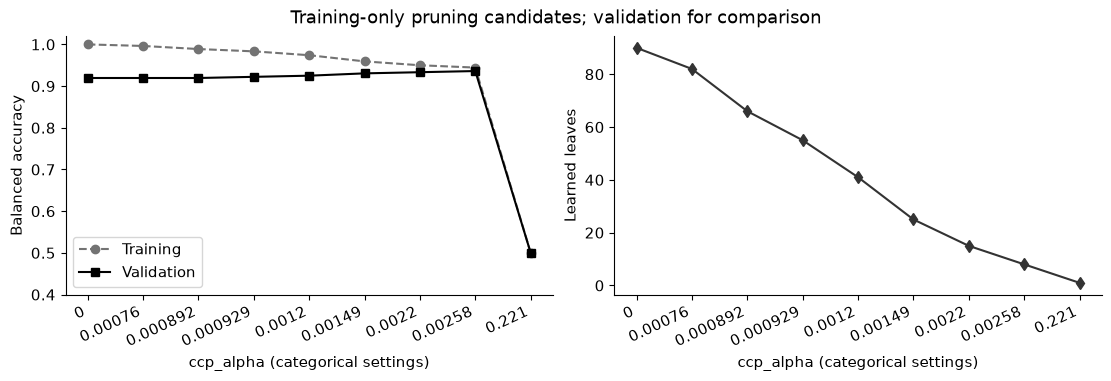

,setting,train_bal_acc,val_bal_acc,val_accuracy,val_log_loss,depth,leaves
0,0.0,1.0000,0.9194,0.9194,2.9035,15,90
1,0.0007598039215686275,0.9963,0.9194,0.9194,2.7146,13,82
2,0.000892453865014841,0.9889,0.9194,0.9194,2.2515,12,66
3,0.0009292758424702847,0.9833,0.9222,0.9222,1.7911,12,55
4,0.0011962273988417775,0.9741,0.9250,0.9250,1.5246,12,41
5,0.0014913534858387797,0.9593,0.9306,0.9306,0.9447,10,25
6,0.0022023204271477024,0.9500,0.9333,0.9333,0.2955,7,15
7,0.0025753641746451552,0.9444,0.9361,0.9361,0.2088,6,8
8,0.2207884021815012,0.5000,0.5000,0.5000,0.6931,0,1


Candidate alpha range: 0.0 to 0.2207884021815012


In [18]:
pruning_path=DecisionTreeClassifier(random_state=SEED).cost_complexity_pruning_path(X_train,y_train)
alpha_values=np.unique(np.quantile(pruning_path.ccp_alphas,np.linspace(0,1,9))).tolist()
pruning_table,pruning_models=sweep('ccp_alpha',alpha_values,title='Training-only pruning candidates; validation for comparison')
assert all(a.get_n_leaves()>=b.get_n_leaves() for a,b in zip(pruning_models,pruning_models[1:]))
print('Candidate alpha range:',alpha_values[0], 'to',alpha_values[-1])


<a id="monotonic"></a>
## Experiment: `monotonic_cst` — encode an ordered-effect assumption

Circular moon coordinates have no defensible monotonic class effect. We use a different, explicitly constructed binary task: independent dimensionless load and resistance indices in [0,1], with positive-class probability `sigmoid(5*load - 4*resistance - 0.5)` and Bernoulli labels. The true simulated probability increases with load and decreases with resistance. This is an invented probability model, not a validated failure law. We use no missing values, one binary output and no multiclass target.

The constrained tree uses `[1, -1]`, meaning positive-class probability must be nondecreasing in load and nonincreasing in resistance while the other feature stays fixed. The unconstrained comparison uses `None`. Both share depth six, leaf size eight, seed and development split. A constraint expresses an assumption, not proof that the assumption is scientifically correct or that probabilities are calibrated. It can reduce flexibility and may worsen a validation score even when it improves shape consistency.

**Predict first:** will an unconstrained finite-sample tree always preserve the known simulated ordering? The line plots hold the other index at 0.5. A denser two-dimensional grid counts order violations across adjacent points; this checks a visible consequence rather than merely confirming that the parameter was accepted. The constraint's general guarantee comes from its implementation and stated scope, not from this finite grid test alone.


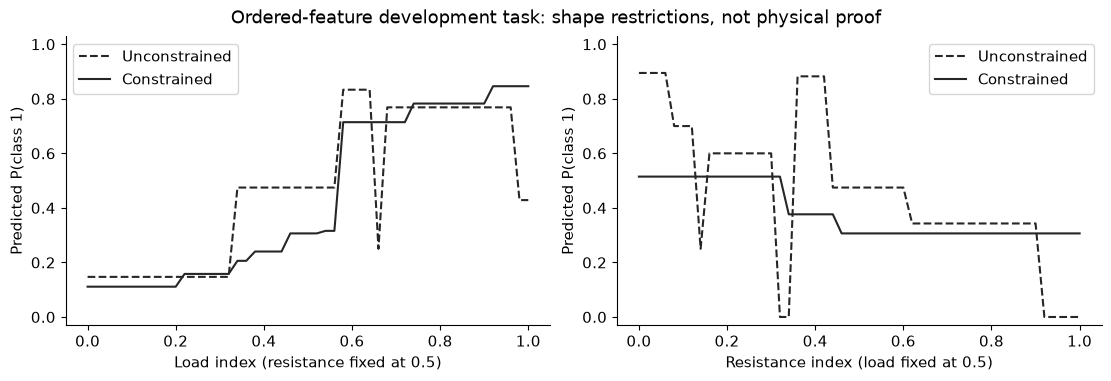

,model,load_order_violations,resistance_order_violations,val_bal_acc,val_brier
0,Unconstrained,96,146,0.7302,0.2009
1,Constrained,0,0,0.7454,0.1761


In [19]:
mono_rng=np.random.default_rng(SEED+40)
Xm=mono_rng.uniform(size=(1800,2))
true_probability=1/(1+np.exp(-(5*Xm[:,0]-4*Xm[:,1]-.5)))
ym=mono_rng.binomial(1,true_probability)
Xm_tr,Xm_va,ym_tr,ym_va=train_test_split(Xm,ym,test_size=.25,stratify=ym,random_state=SEED)
mono_models=[]; mono_rows=[]
grid=np.linspace(0,1,51)
xx,yy=np.meshgrid(grid,grid,indexing='ij'); grid_points=np.c_[xx.ravel(),yy.ravel()]
for label,constraints in [('Unconstrained',None),('Constrained',[1,-1])]:
    model=DecisionTreeClassifier(max_depth=6,min_samples_leaf=8,random_state=SEED,monotonic_cst=constraints).fit(Xm_tr,ym_tr)
    surface=model.predict_proba(grid_points)[:,1].reshape(xx.shape)
    load_violations=int((np.diff(surface,axis=0)<-1e-12).sum())
    resistance_violations=int((np.diff(surface,axis=1)>1e-12).sum())
    mono_models.append(model)
    mono_rows.append({'model':label,'load_order_violations':load_violations,
      'resistance_order_violations':resistance_violations,
      'val_bal_acc':balanced_accuracy_score(ym_va,model.predict(Xm_va)),
      'val_brier':brier_score_loss(ym_va,model.predict_proba(Xm_va)[:,1])})
assert mono_rows[1]['load_order_violations']==mono_rows[1]['resistance_order_violations']==0
assert mono_rows[0]['load_order_violations']+mono_rows[0]['resistance_order_violations']>0
fig,axes=plt.subplots(1,2,figsize=(11,3.7))
for label,model,style in zip(['Unconstrained','Constrained'],mono_models,['--','-']):
    axes[0].plot(grid,model.predict_proba(np.c_[grid,np.full_like(grid,.5)])[:,1],style,label=label,color='.15')
    axes[1].plot(grid,model.predict_proba(np.c_[np.full_like(grid,.5),grid])[:,1],style,label=label,color='.15')
axes[0].set(xlabel='Load index (resistance fixed at 0.5)',ylabel='Predicted P(class 1)')
axes[1].set(xlabel='Resistance index (load fixed at 0.5)',ylabel='Predicted P(class 1)')
for ax in axes:ax.set_ylim(-.03,1.03); ax.legend()
fig.suptitle('Ordered-feature development task: shape restrictions, not physical proof'); plt.show()
display(pd.DataFrame(mono_rows).round(4)); mark('monotonic_cst')


<a id="interaction"></a>
## Interactions and a predeclared final choice

One-factor experiments explain controls but can miss interactions: a leaf-support restriction may make a depth cap irrelevant, and a shallow depth may prevent a large leaf budget from being used. We now evaluate the **24 combinations fixed in the setup cell**: six depth choices and four integer leaf minima, with all other constructor settings at their stated defaults and seed 418. These are the only candidates eligible for the final model. The earlier auxiliary experiments and pruning curves remain mechanistic explorations.

The heatmap annotates validation balanced accuracy, so colour is supplementary. If scores tie exactly, prefer fewer learned leaves, then shallower depth, then the earlier grid entry. This deterministic tie rule is fixed here before the final test is opened. The selected setting is not claimed to be statistically superior to every near neighbour; a small validation difference may be noise. A production comparison would use more independent groups or repeated development splits with budgets and decision costs specified.

**Predict first:** will the best depth necessarily be the same at leaf minima 1 and 50? Read the selected configuration and development score before continuing. Do not change this grid in response to the final test result. For further exploration, begin a new development experiment and treat the revealed test as spent.


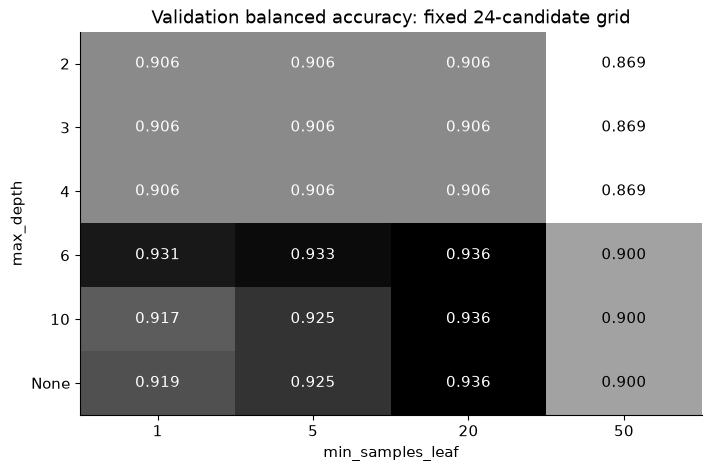

Selected hyperparameters: {'max_depth': 6, 'min_samples_leaf': 20}
Selection used validation only: {'max_depth': '6', 'min_samples_leaf': 20, 'train_bal_acc': 0.9444444444444444, 'val_bal_acc': 0.9361111111111111, 'val_accuracy': 0.9361111111111111, 'val_log_loss': 0.5435154569200638, 'depth': 6, 'leaves': np.int64(23)}
Executed constructor coverage: 13 of 13 ['ccp_alpha', 'class_weight', 'criterion', 'max_depth', 'max_features', 'max_leaf_nodes', 'min_impurity_decrease', 'min_samples_leaf', 'min_samples_split', 'min_weight_fraction_leaf', 'monotonic_cst', 'random_state', 'splitter']


In [20]:
selection_rows=[]; selection_models=[]
heat=np.empty((len(FINAL_DEPTHS),len(FINAL_LEAVES)))
for i,depth in enumerate(FINAL_DEPTHS):
    for j,leaf_min in enumerate(FINAL_LEAVES):
        model=DecisionTreeClassifier(max_depth=depth,min_samples_leaf=leaf_min,random_state=SEED).fit(X_train,y_train)
        result=comparison(model)
        selection_rows.append({'max_depth':str(depth),'min_samples_leaf':leaf_min,**result})
        selection_models.append(model); heat[i,j]=result['val_bal_acc']
choice=max(range(len(selection_rows)),key=lambda i:(selection_rows[i]['val_bal_acc'],
           -selection_rows[i]['leaves'],-selection_rows[i]['depth'],-i))
selected_dev_model=selection_models[choice]
best_params={k:selected_dev_model.get_params()[k] for k in ['max_depth','min_samples_leaf']}
selected_validation=selection_rows[choice]
fig,ax=plt.subplots(figsize=(7,4.6))
ax.imshow(heat,cmap='Greys',vmin=heat.min(),vmax=heat.max(),aspect='auto')
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j,i,f'{heat[i,j]:.3f}',ha='center',va='center',
                color='white' if heat[i,j]>(heat.min()+heat.max())/2 else 'black')
ax.set_xticks(range(len(FINAL_LEAVES)),FINAL_LEAVES); ax.set_yticks(range(len(FINAL_DEPTHS)),list(map(str,FINAL_DEPTHS)))
ax.set(xlabel='min_samples_leaf',ylabel='max_depth',title='Validation balanced accuracy: fixed 24-candidate grid')
plt.show()
print('Selected hyperparameters:',best_params)
print('Selection used validation only:',selected_validation)
assert covered==set(actual_params),('Missing experiment',set(actual_params)-covered)
print('Executed constructor coverage:',len(covered),'of',len(actual_params),sorted(covered))
assert not TEST_REVEALED


<a id="final-test"></a>
## One final assessment after refitting the selected configuration

The selection is complete. We refit that exact configuration on the combined training-plus-validation development rows, then open the sealed final set once. Since the chosen leaf setting is an integer, combining development rows preserves its literal count meaning. A fractional leaf minimum would scale with the new fitting-set size and should be documented explicitly.

The final dummy baseline is also fitted on the combined development labels. Both models are assessed together in the same cell; the resulting scores are the final assessment for this synthetic task. The test set does not choose the model, threshold, class weights, features or pruning path. Confidence intervals and population-level replication are outside this first exemplar; a single finite test score is not an exact population performance value.

**Figure caption and textual alternative:** the final confusion matrices show actual observed counts with rows as true class and columns as predicted class. The adjacent numeric report supplies accuracy, balanced accuracy, log loss and Brier score for both frozen fitted models. Use the count tables and metrics if the figure is unavailable.


Prior baseline confusion counts: [[180, 0], [180, 0]]
Selected tree confusion counts: [[170, 10], [14, 166]]


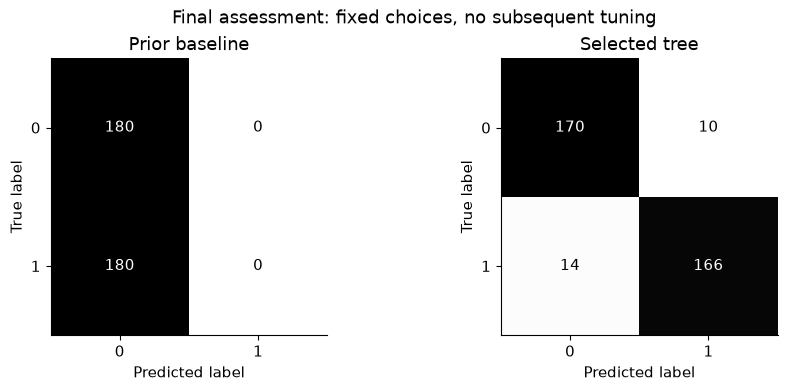

,model,accuracy,balanced_accuracy,log_loss,brier
0,Prior baseline,0.50000,0.50000,0.69315,0.25000
1,Selected tree,0.93333,0.93333,0.63578,0.05504


EXECUTION_SUMMARY_JSON: {"constructor_parameters": ["ccp_alpha", "class_weight", "criterion", "max_depth", "max_features", "max_leaf_nodes", "min_impurity_decrease", "min_samples_leaf", "min_samples_split", "min_weight_fraction_leaf", "monotonic_cst", "random_state", "splitter"], "elapsed_seconds": 1.64, "example_id": "code_001", "final_metrics": [{"accuracy": 0.5, "balanced_accuracy": 0.5, "brier": 0.25, "log_loss": 0.6931471805599453, "model": "Prior baseline"}, {"accuracy": 0.9333333333333333, "balanced_accuracy": 0.9333333333333333, "brier": 0.05504416216048023, "log_loss": 0.6357753520094058, "model": "Selected tree"}], "hardware": "Darwin arm64 CPU", "seed": 418, "selected_parameters": {"max_depth": 6, "min_samples_leaf": 20}, "selection_validation_balanced_accuracy": 0.9361111111111111, "split_rows": {"test": 360, "train": 1080, "validation": 360}, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.1

In [21]:
import json
assert not TEST_REVEALED, 'Restart and rerun cleanly; do not use this cell for repeated tuning.'
final_tree=DecisionTreeClassifier(**best_params,random_state=SEED).fit(X_all[dev_ids],y_all[dev_ids])
final_dummy=DummyClassifier(strategy='prior').fit(X_all[dev_ids],y_all[dev_ids])
X_test,y_test=X_all[test_ids],y_all[test_ids]
TEST_REVEALED=True
final_rows=[]
fig,axes=plt.subplots(1,2,figsize=(9,3.8))
for ax,(name,model) in zip(axes,[('Prior baseline',final_dummy),('Selected tree',final_tree)]):
    result={'model':name,**scores(model,X_test,y_test),
            'brier':brier_score_loss(y_test,model.predict_proba(X_test)[:,1])}
    final_rows.append(result)
    cm=confusion_matrix(y_test,model.predict(X_test),labels=[0,1])
    print(name,'confusion counts:',cm.tolist())
    ConfusionMatrixDisplay(cm,display_labels=[0,1]).plot(ax=ax,colorbar=False,cmap='Greys',values_format='d')
    ax.set_title(name)
fig.suptitle('Final assessment: fixed choices, no subsequent tuning'); plt.show()
display(pd.DataFrame(final_rows).round(5))
EXECUTION_SUMMARY={'example_id':'code_001','versions':VERSIONS,'seed':SEED,
 'hardware':platform.system()+' '+platform.machine()+' CPU',
 'split_rows':{'train':len(train_ids),'validation':len(val_ids),'test':len(test_ids)},
 'constructor_parameters':sorted(covered),'selected_parameters':best_params,
 'selection_validation_balanced_accuracy':selected_validation['val_bal_acc'],
 'final_metrics':final_rows,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:',json.dumps(EXECUTION_SUMMARY,sort_keys=True))


## Interpret the final result and decide what it supports

Compare the executed tree metrics with the prior baseline, then inspect false positives and false negatives in the counts. If balanced accuracy improves but log loss remains large, the model can rank or classify many points successfully while making some overconfident leaf assignments. If the final score is lower than the selected validation score, finite samples and selection optimism are plausible explanations; it is not permission to pick another model using this test. The table records what this run observed, not what your real project will obtain.

Trees are useful when conditional threshold rules, nonlinear interactions and straightforward numeric preprocessing fit the task. Their limitations include unstable partitions, greedy choices, axis-aligned boundaries, overconfident small leaves and weak extrapolation. A readable tree is still a predictive model, not an identified causal explanation. For higher accuracy, bagging or boosting may be a sensible next controlled comparison, with interpretability and inference cost reassessed.

For real maintenance data, replace abstract coordinates with valid measurements available before the decision. Define the outcome, horizon and cost of an unnecessary inspection versus a missed failure. Preserve entity identifiers for grouped splitting but do not casually use them as predictive features. Check units, missingness, category encoding, target delay, repeated observations and domain support. Compare calibration and subgroup errors; a synthetic notebook cannot validate a safety-critical structural decision.

## Troubleshooting and operational checks

- **Version/API assertion fails:** create the pinned environment and select its kernel. If intentionally upgrading, inspect the new constructor and rerun every coverage experiment before updating the registry. The default documentation may show a newer maintenance release.
- **Only one class or undefined precision:** inspect class counts after splitting. Stratification and adequate data are necessary; `zero_division=0` here makes a diagnostic printable, not evidence that the issue is harmless.
- **Perfect training accuracy but weak validation:** inspect small leaves, noise features and entity leakage before adding complexity. Try stronger leaf support or pruning inside development data.
- **Probabilities are exactly zero or one:** check leaf support and probability metrics. Do not call the output calibrated without a separate valid calibration study.
- **Plot labels overlap on a small screen:** expand the output; the notebook uses separate labelled panels and numeric tables. Restart-and-run-all is the supported way to recover hidden or out-of-order state.
- **Monotonic fit rejects your real target:** confirm the target is a supported binary single-output task and that your ordered features, constraints and data handling satisfy the installed API. A constraint cannot repair incorrect labels or a false scientific assumption.
- **Execution is slow:** use the documented CPU-sized data first. The notebook does not require increasing sample counts, installing Graphviz or downloading a dataset.

<a id="exercises"></a>
## Exercises: predict, change one factor, explain the outcome

Keep training/validation as your sandbox. The executed final test has now been revealed; do not use it as a selection signal for these exercises. Save your experiments in a new notebook copy and use a genuinely fresh assessment dataset if you want a new final generalization claim.

1. **Trace a decision:** choose one validation record, write the root-to-leaf questions from `export_text`, and calculate its leaf probability from training labels. Compare with `apply` and `predict_proba`. Explain why a correct trace need not imply a correct prediction.
2. **Underfit versus overfit:** before running, sketch expected training and validation curves for depths 1 through 12. Repeat with minimum leaf count 30. Which changes affect small regions, and which remove an entire level of questions?
3. **Noisy labels:** generate a new, independently seeded development dataset, flip 15% of its *training* labels using an explicit RNG, and hold its validation labels fixed. Compare unrestricted and supported-leaf trees. Do not flip validation labels and then interpret the result as performance against clean truth.
4. **Counts versus fractions:** halve the training sample while preserving class balance. Compare `min_samples_leaf=20` with `min_samples_leaf=0.02`. Compute the effective required counts and predict how their relationship changes before fitting.
5. **Weighting and costs:** use only the auxiliary imbalanced development data to compare three declared false-negative/false-positive cost ratios. Choose the ratios before seeing results. Contrast training class weights with applying a decision threshold to fixed probabilities; assess calibration separately.
6. **Constraint validity:** reverse the load constraint in the auxiliary monotonic task and compare ordering checks, validation Brier score and the known generating probability. Explain why a perfectly enforced constraint can still be the wrong scientific assumption.
7. **Stability:** perturb 5% of training observations or bootstrap training rows, refit a fixed depth-four tree and compare predictions on the same validation records. Report distributions over predeclared seeds rather than a best seed.
8. **Adapt a real problem:** write a one-page specification covering observation unit, target horizon, information cutoff, group/time split, baseline, missing/category handling, metric, calibration, subgroup coverage, inspection cost, documentation and fallback. State what evidence would be needed before deployment.

<details>
<summary>Optional hints and reference observations — open after predicting</summary>

Leaf support and depth constrain different aspects of the partition. Fractions scale with the total fitting-row count; integers do not. Training-only label corruption can increase the gap between fit quality and validation quality. Weights and thresholds are not equivalent procedures: weights change the learned partition and leaf composition, while a threshold changes action selection for a fixed score. Enforcing the wrong monotonic direction does not make the data-generating process obey it. Random-seed spread on one split is narrower evidence than replication across new entities or populations. Exact numerical outcomes should come from the cells you run, not from these qualitative hints.

</details>

## Sources and provenance

All data are generated locally by the named scikit-learn functions or the explicit NumPy probability model above. Figures are calculated from those data and the fitted estimators; there are no borrowed result images. The mechanism diagram uses invented leaf counts clearly separated from fitted results. The [registry](../CODE_EXAMPLES.md#code_001), [authoring guide](../AUTHORING_GUIDE.md) and [execution report](../EXECUTION_REPORT.md) document stable linking and verification.

Primary implementation references checked for this example: [DecisionTreeClassifier API](https://scikit-learn.org/1.9/modules/generated/sklearn.tree.DecisionTreeClassifier.html), [tree concepts and assumptions](https://scikit-learn.org/1.9/modules/tree.html), [cost-complexity pruning](https://scikit-learn.org/1.9/auto_examples/tree/plot_cost_complexity_pruning.html), and [split utility](https://scikit-learn.org/1.9/modules/generated/sklearn.model_selection.train_test_split.html). Record the tested patch version rather than assuming a live maintenance URL is an immutable software snapshot.
